# Autoencoders (PyTorch)

In this lab, you will build: Autoencoders, denoising autoencoder, and convolutional autoencoders

# Learning Objectives

By the end of this lab, you should be able to:

- explain what an autoencoder is
- understand the role of the encoder and decoder
- interpret the bottleneck or latent representation
- train a simple dense autoencoder
- train a denoising autoencoder
- train a convolutional autoencoder
- compare reconstruction quality across different architectures

# Introduction

**Autoencoders** are a particular type of neural network that compresses the data into a **latent vector**, often denoted $z$ in the literature, with the goal of preserving the opportunity to recreate the exact same image in the future.

Because autoencoders learn representations instead of labels, they belong to **representation learning**, a subfield of machine learning, but not necessarily deep learning.

## Architecture

Autoencoders consist of two networks:

- an **encoder**, which compresses the input
- a **decoder**, which reconstructs the input from the compressed representation

This notebook explores three versions:
1. a simple dense autoencoder
2. a denoising autoencoder
3. a convolutional autoencoder

# Step 1 — Notebook Setup

We start with the PyTorch equivalent of the original environment setup and imports.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

print("PyTorch version:", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.11.0+cu128
Using device: cuda


# Step 2 — Loading the Data

We load MNIST, but without labels, because representation learning is **unsupervised**, or **self-supervised**, which is the preferred term.


In [ ]:
# Load MNIST and normalize pixel values
train_dataset_raw = datasets.MNIST(root="./data", train=True, download=True)
test_dataset_raw = datasets.MNIST(root="./data", train=False, download=True)

x_train = train_dataset_raw.data.numpy() / 255.0
x_test = test_dataset_raw.data.numpy() / 255.0

x_train = x_train.astype("float32")
x_test = x_test.astype("float32")

print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.58MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.82MB/s]


x_train shape: (60000, 28, 28)
x_test shape: (10000, 28, 28)


# Part 1 — A Simple Autoencoder

We begin with the simplest possible autoencoder.

The `encoder` is a sequential neural network with $28 \times 28$ input neurons, $100$ neurons in the second layer and $30$ in the third.

The third layer is called the **bottleneck**.  
Feel free to play around with this variable to see how it affects the results.

In [ ]:
# Simple dense encoder
class SimpleEncoder(nn.Module):
    def __init__(self, bottleneck_dim=30):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 100),
            nn.ReLU(),
            nn.Linear(100, bottleneck_dim),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.net(x)

encoder = SimpleEncoder(bottleneck_dim=30).to(device)
print(encoder)
total_params = sum(p.numel() for p in encoder.parameters())
print(f"Total parameters: {total_params:,}")

SimpleEncoder(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=100, bias=True)
    (2): ReLU()
    (3): Linear(in_features=100, out_features=30, bias=True)
    (4): ReLU()
  )
)
Total parameters: 81,530


The decoder is the same, but in reverse order.

Note that in Keras the decoder needs to know the input shape at this point (`input_shape=[30]`). In PyTorch this is implicit: `nn.Linear(30, 100)` already fixes the expected input dimension.  
The input shape of the decoder is the shape of $z$, also called `zDim` in some implementations.

In [ ]:
# Simple dense decoder
class SimpleDecoder(nn.Module):
    def __init__(self, bottleneck_dim=30):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(bottleneck_dim, 100),
            nn.ReLU(),
            nn.Linear(100, 28 * 28),
            nn.Sigmoid(),
        )

    def forward(self, x):
        x = self.net(x)
        return x.view(-1, 28, 28)

decoder = SimpleDecoder(bottleneck_dim=30).to(device)
print(decoder)
total_params = sum(p.numel() for p in decoder.parameters())
print(f"Total parameters: {total_params:,}")

SimpleDecoder(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=100, bias=True)
    (1): ReLU()
    (2): Linear(in_features=100, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Total parameters: 82,284


Now we stack the encoder and decoder together for training.

In [ ]:
# Full simple autoencoder
class Autoencoder(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

stacked_autoencoder = Autoencoder(encoder, decoder).to(device)
total_params = sum(p.numel() for p in stacked_autoencoder.parameters())
print(f"Total parameters: {total_params:,}")

Total parameters: 163,814


We use **binary cross entropy** instead of categorical cross entropy.

The reason is that we are not classifying latent vectors into classes.  
Instead, the network is trying to reconstruct pixel values, that is, whether a pixel should be activated or not.

Since the decoder already applies a `Sigmoid` at its output, we use `nn.BCELoss` (which expects probabilities), not `nn.BCEWithLogitsLoss` (which expects raw logits).

**Exercise:** define `criterion` and `optimizer` yourself below, exactly like you did in Lab 1 (`criterion` / `optimizer` for `BinaryCNN`) and Lab 2 (`criterion` / `optimizer` for `BaselineCNN`) — only the loss function changes.

In [ ]:
# TODO: define criterion and optimizer for the simple autoencoder
# - criterion: nn.BCELoss() (the decoder already applies Sigmoid, so BCELoss expects
#   probabilities in [0, 1], not raw logits — unlike BCEWithLogitsLoss in Lab 1)
# - optimizer: optim.Adam(stacked_autoencoder.parameters())
criterion = ...
optimizer = ...

Notice how the input and the target are the same:

- input = `x_train`
- target = `x_train`

This is the basic principle of autoencoder training.

**Exercise — the training loop:** write `train_autoencoder`, adapting the training loop you built in Lab 1 (`train_binary_model`) and Lab 2 (`train_with_early_stopping`).

Key differences for an autoencoder:
- the model takes a batch `xb` as input and must reconstruct `yb` (for now `x_train_target = x_train`, so input and target are literally the same images)
- there is no `argmax` / accuracy to compute here — only the reconstruction loss
- `criterion` compares `outputs` (the reconstruction produced by the model) with `yb` (the target image)

Complete the **training** loop and the **validation** loop below, following the same pattern as before: move the batch to `device`, then `zero_grad()` / forward / `loss.backward()` / `step()` for training (no gradient step for validation), and accumulate `running_loss` weighted by batch size (`loss.item() * xb.size(0)`).

In [ ]:
def train_autoencoder(model, x_train_data, x_train_target, x_val_data, x_val_target,
                       criterion, optimizer, device, epochs=10, batch_size=32):
    train_dataset = TensorDataset(torch.tensor(x_train_data), torch.tensor(x_train_target))
    val_dataset = TensorDataset(torch.tensor(x_val_data), torch.tensor(x_val_target))
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    history = {"loss": [], "val_loss": []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        total = 0
        for xb, yb in train_loader:
            # TODO: training step (see Lab 1 / Lab 2 training loops)
            # - move xb, yb to device
            # - optimizer.zero_grad()
            # - outputs = model(xb)
            # - loss = criterion(outputs, yb)
            # - loss.backward()
            # - optimizer.step()
            # - accumulate: running_loss += loss.item() * xb.size(0) ; total += xb.size(0)
            pass
        train_loss = running_loss / total

        model.eval()
        val_running_loss = 0.0
        val_total = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                # TODO: validation step (no zero_grad / backward / step here)
                # - move xb, yb to device
                # - outputs = model(xb)
                # - loss = criterion(outputs, yb)
                # - accumulate: val_running_loss += loss.item() * xb.size(0) ; val_total += xb.size(0)
                pass
        val_loss = val_running_loss / val_total

        history["loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        print(f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - val_loss: {val_loss:.4f}")

    return history

In [ ]:
# Train the simple autoencoder
history = train_autoencoder(stacked_autoencoder, x_train, x_train, x_test, x_test,
                             criterion, optimizer, device, epochs=10)

Let's now look at how the autoencoder reconstructs images.

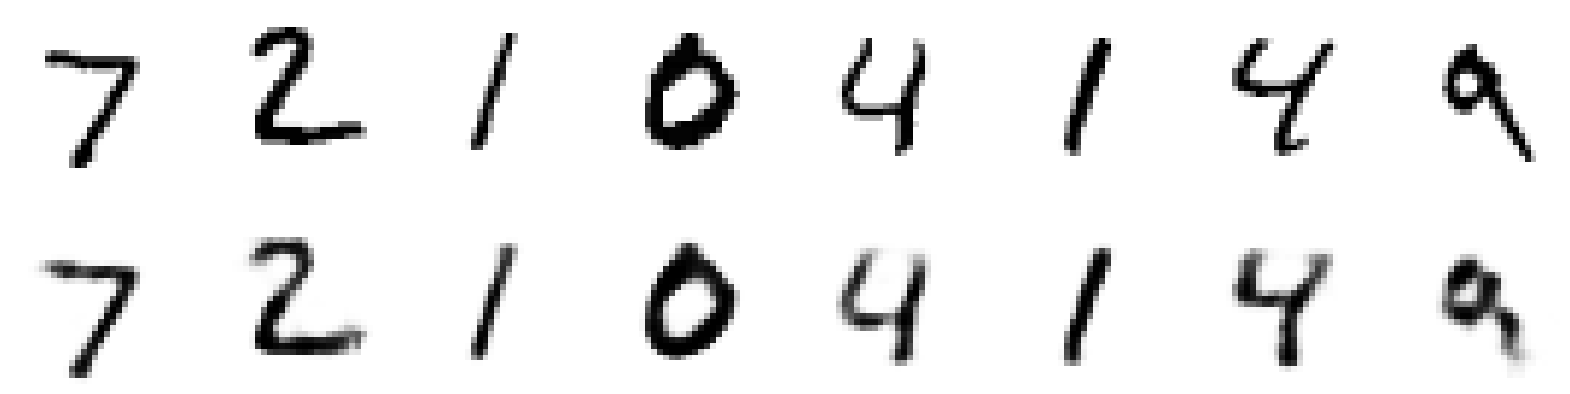

In [ ]:
stacked_autoencoder.eval()

plt.figure(figsize=(20, 5))
for i in range(8):
    plt.subplot(2, 8, i + 1)
    with torch.no_grad():
        inp = torch.tensor(x_test[i]).reshape(1, 28, 28).to(device)
        pred = stacked_autoencoder(inp).cpu().numpy()
    plt.imshow(x_test[i], cmap="binary")
    plt.axis("off")

    plt.subplot(2, 8, i + 8 + 1)
    plt.imshow(pred.reshape((28, 28)), cmap="binary")
    plt.axis("off")
plt.show()

We can also inspect how much information is stored in the bottleneck representation.

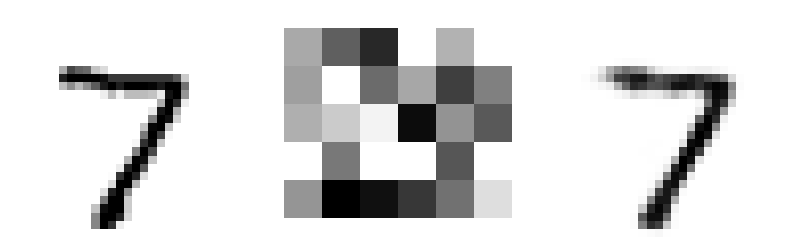

In [ ]:
i = 0  # change this number

plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(x_test[i], cmap="binary")
plt.axis("off")

with torch.no_grad():
    inp = torch.tensor(x_test[i]).reshape(1, 28, 28).to(device)
    z = encoder(inp).cpu().numpy()
    recon = decoder(torch.tensor(z).to(device)).cpu().numpy()

plt.subplot(1, 3, 2)
plt.imshow(z.reshape((5, 6)), cmap="binary")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(recon.reshape((28, 28)), cmap="binary")
plt.axis("off")
plt.show()

In [ ]:
30 / (28 * 28), 1 - 30 / (28 * 28)

(0.03826530612244898, 0.9617346938775511)

That's **96.2% compression** — pretty amazing.

# Part 2 — Denoising Autoencoder

The next application we explore is the **denoising autoencoder**.

The idea is simple:
- corrupt the input image with noise
- ask the autoencoder to reconstruct the original clean image

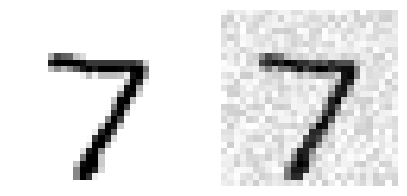

In [ ]:
# Show an example of a clean image and a noisy version
plt.figure(figsize=(5, 10))
plt.subplot(1, 2, 1)
plt.imshow(x_test[0], cmap="binary")
plt.axis("off")

plt.subplot(1, 2, 2)
noise = np.random.random((28, 28)) / 4
plt.imshow(x_test[0] + noise, cmap="binary")
plt.axis("off")
plt.show()

In machine learning, this kind of noise can be catastrophic.  
Luckily, autoencoders can be trained to remove it.

By applying noise to the images fed into the encoder and keeping the clean image as the desired output, the autoencoder can learn a denoising transformation.

Let's build such an autoencoder.

In [ ]:
# Denoising encoder
class DenoisingEncoder(nn.Module):
    def __init__(self, bottleneck_dim=30):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.ReLU(),
            nn.Linear(100, bottleneck_dim),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.net(x)

encoder = DenoisingEncoder(bottleneck_dim=30).to(device)
print(encoder)

DenoisingEncoder(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=100, bias=True)
    (2): ReLU()
    (3): Linear(in_features=100, out_features=100, bias=True)
    (4): ReLU()
    (5): Linear(in_features=100, out_features=30, bias=True)
    (6): ReLU()
  )
)


In [ ]:
# Denoising decoder
class DenoisingDecoder(nn.Module):
    def __init__(self, bottleneck_dim=30):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(bottleneck_dim, 100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.ReLU(),
            nn.Linear(100, 28 * 28),
            nn.Sigmoid(),
        )

    def forward(self, x):
        x = self.net(x)
        return x.view(-1, 28, 28)

decoder = DenoisingDecoder(bottleneck_dim=30).to(device)
print(decoder)

DenoisingDecoder(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=100, bias=True)
    (1): ReLU()
    (2): Linear(in_features=100, out_features=100, bias=True)
    (3): ReLU()
    (4): Linear(in_features=100, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [ ]:
# Full denoising autoencoder
stacked_autoencoder = Autoencoder(encoder, decoder).to(device)
total_params = sum(p.numel() for p in stacked_autoencoder.parameters())
print(f"Total parameters: {total_params:,}")

Total parameters: 184,014


In [ ]:
# Compile the denoising autoencoder
criterion = nn.BCELoss()
optimizer = optim.Adam(stacked_autoencoder.parameters())

Now create noisy versions of the dataset.

In [ ]:
# Add random noise to the images
x_train_noise = x_train + ((np.random.random(x_train.shape)) / 4).astype("float32")
x_test_noise = x_test + ((np.random.random(x_test.shape)) / 4).astype("float32")

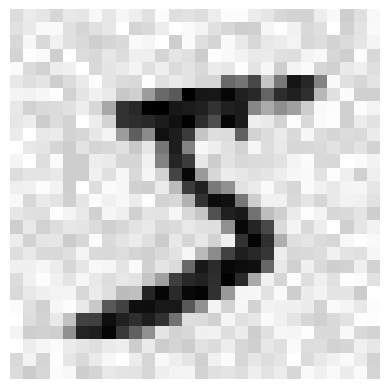

In [ ]:
plt.imshow(x_train_noise[0], cmap="binary")
plt.axis("off")
plt.show()

And finally train the denoising autoencoder with:
- noisy input images
- clean target images

In [ ]:
# Train on noisy inputs and clean targets
history = train_autoencoder(stacked_autoencoder, x_train_noise, x_train, x_test_noise, x_test,
                             criterion, optimizer, device, epochs=10)

Epoch 1/10 - loss: 0.2007 - val_loss: 0.1517
Epoch 2/10 - loss: 0.1415 - val_loss: 0.1324
Epoch 3/10 - loss: 0.1265 - val_loss: 0.1197
Epoch 4/10 - loss: 0.1185 - val_loss: 0.1145
Epoch 5/10 - loss: 0.1137 - val_loss: 0.1107
Epoch 6/10 - loss: 0.1107 - val_loss: 0.1087
Epoch 7/10 - loss: 0.1080 - val_loss: 0.1061
Epoch 8/10 - loss: 0.1054 - val_loss: 0.1027
Epoch 9/10 - loss: 0.1035 - val_loss: 0.1022
Epoch 10/10 - loss: 0.1022 - val_loss: 0.1010


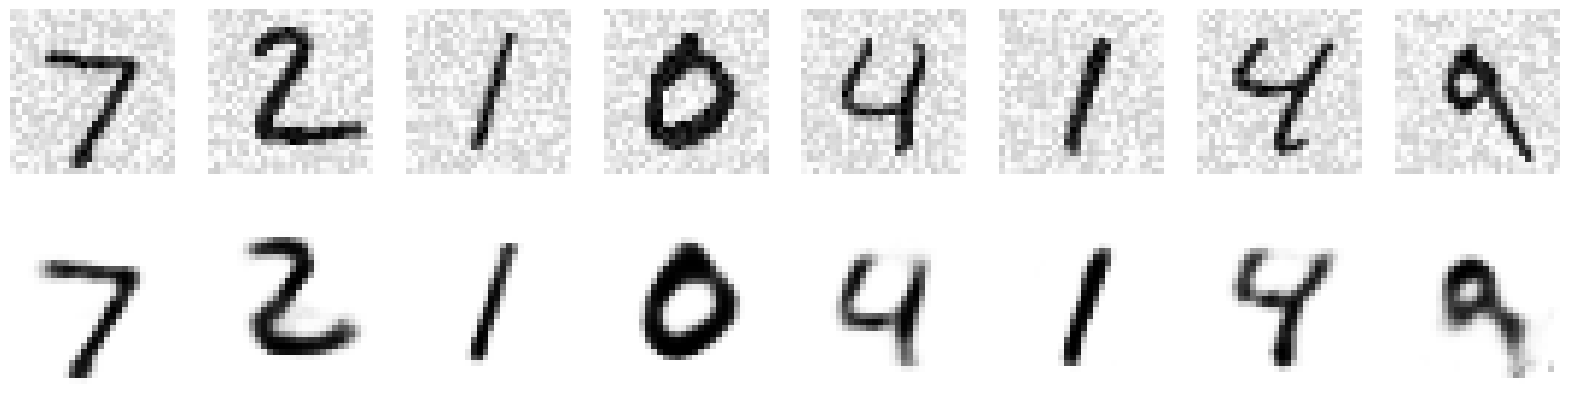

In [ ]:
# Compare noisy inputs and denoised outputs
stacked_autoencoder.eval()

plt.figure(figsize=(20, 5))
for i in range(8):
    plt.subplot(2, 8, i + 1)
    plt.imshow(x_test_noise[i], cmap="binary")
    plt.axis("off")

    plt.subplot(2, 8, i + 8 + 1)
    with torch.no_grad():
        inp = torch.tensor(x_test_noise[i]).reshape(1, 28, 28).to(device)
        pred = stacked_autoencoder(inp).cpu().numpy()
    plt.imshow(pred.reshape((28, 28)), cmap="binary")
    plt.axis("off")
plt.show()

Mindblowing!

# Part 3 — Convolutional Autoencoder

Apart from data compression, autoencoders can also be used for self-supervised image representation learning.

In this last part, we switch from dense layers to **convolutional layers**, which are usually much better suited to images because they preserve spatial structure.

Noise is added again before training the convolutional autoencoder.

In [ ]:
# Add random noise to the images
x_train_noise = x_train + ((np.random.random(x_train.shape)) / 4).astype("float32")
x_test_noise = x_test + ((np.random.random(x_test.shape)) / 4).astype("float32")

# Important: clip back to [0, 1] after adding noise.
# nn.BCELoss requires targets strictly in [0, 1] (it's a Bernoulli log-likelihood);
# without clipping, noisy pixels can exceed 1.0, which raises a CUDA
# "device-side assert triggered" error inside binary_cross_entropy on GPU.
x_train_noise = np.clip(x_train_noise, 0.0, 1.0)
x_test_noise = np.clip(x_test_noise, 0.0, 1.0)

**Build the Convolutional Encoder**

Three convolution + max-pooling blocks progressively reduce the `28 x 28` image down to a `64 x 3 x 3` latent representation (576 values — the bottleneck).

**Exercise:** this is the same `Conv2d → ReLU → MaxPool2d` pattern you used for `BinaryCNN` (Lab 1) and `BaselineCNN` (Lab 2) — just with `padding=1` so the spatial size exactly halves at each pooling step. Complete `self.net` below with three blocks (`1→16`, `16→32`, `32→64` channels, `kernel_size=3`, `padding=1`), each followed by `ReLU` and `MaxPool2d(2)`.

In [ ]:
class ConvEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: build self.net as 3 blocks of Conv2d -> ReLU -> MaxPool2d(2)
        # channels: 1->16, 16->32, 32->64 ; kernel_size=3, padding=1 for every conv
        # (same pattern as BinaryCNN in Lab 1 / BaselineCNN in Lab 2)
        self.net = nn.Sequential(
            # YOUR CODE HERE
        )

    def forward(self, x):
        x = x.unsqueeze(1)  # (N, 28, 28) -> (N, 1, 28, 28)
        return self.net(x)


encoder = ConvEncoder().to(device)
print(encoder)

with torch.no_grad():
    sample_out = encoder(torch.tensor(x_test[0]).reshape(1, 28, 28).to(device))
print("Latent shape:", sample_out.shape)  # (1, 64, 3, 3)

**Build the Convolutional Decoder**

We use **transposed convolutions** to go back from `64 x 3 x 3` to `28 x 28`, mirroring the encoder's downsampling with the correct `padding` / `output_padding` so the shapes match exactly (`3 -> 7 -> 14 -> 28`).

In [ ]:
class ConvDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # 3x3x64 -> 7x7x32  (Keras Conv2DTranspose(..., padding="valid") equivalent)
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=0), nn.ReLU(),
            # 7x7x32 -> 14x14x16  (Keras Conv2DTranspose(..., padding="same") equivalent)
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            # 14x14x16 -> 28x28x1
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1), nn.Sigmoid(),
        )

    def forward(self, x):
        x = self.net(x)
        return x.squeeze(1)  # (N, 1, 28, 28) -> (N, 28, 28)


decoder = ConvDecoder().to(device)
print(decoder)

with torch.no_grad():
    sample_recon = decoder(sample_out)
print("Reconstruction shape:", sample_recon.shape)  # (1, 28, 28)

ConvDecoder(
  (net): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2))
    (1): ReLU()
    (2): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(16, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (5): Sigmoid()
  )
)
Reconstruction shape: torch.Size([1, 28, 28])


**Assemble and Compile the Autoencoder**

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)


stacked_autoencoder = Autoencoder(encoder, decoder).to(device)
total_params = sum(p.numel() for p in stacked_autoencoder.parameters())
print(f"Total parameters: {total_params:,}")

criterion = nn.BCELoss()
optimizer = optim.Adam(stacked_autoencoder.parameters())

Total parameters: 46,529


**rain the Convolutional Autoencoder**

In [ ]:
def train_autoencoder(model, x_train_data, x_train_target, x_val_data, x_val_target,
                       criterion, optimizer, device, epochs=10, batch_size=32):

    def run_training():
        train_dataset = TensorDataset(torch.tensor(x_train_data), torch.tensor(x_train_target))
        val_dataset = TensorDataset(torch.tensor(x_val_data), torch.tensor(x_val_target))
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

        history = {"loss": [], "val_loss": []}

        for epoch in range(epochs):
            model.train()
            running_loss = 0.0
            total = 0
            for xb, yb in train_loader:
                xb, yb = xb.to(device), yb.to(device)
                optimizer.zero_grad()
                outputs = model(xb)
                loss = criterion(outputs, yb)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * xb.size(0)
                total += xb.size(0)
            train_loss = running_loss / total

            model.eval()
            val_running_loss = 0.0
            val_total = 0
            with torch.no_grad():
                for xb, yb in val_loader:
                    xb, yb = xb.to(device), yb.to(device)
                    outputs = model(xb)
                    loss = criterion(outputs, yb)
                    val_running_loss += loss.item() * xb.size(0)
                    val_total += xb.size(0)
            val_loss = val_running_loss / val_total

            history["loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            print(f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - val_loss: {val_loss:.4f}")

        return history

    try:
        return run_training()
    except RuntimeError as e:
        if "cudnn" in str(e).lower() or "cudnn_status" in str(e).lower():
            print("\n[Warning] cuDNN error detected during training.")
            print("Disabling cuDNN and retrying (this run will be slower but should complete)...\n")
            torch.backends.cudnn.enabled = False
            # Re-run the model's forward pass is fine; weights are untouched, we just resume training.
            return run_training()
        else:
            raise


# Train the convolutional autoencoder
history = train_autoencoder(stacked_autoencoder, x_train, x_train, x_test, x_test,
                             criterion, optimizer, device, epochs=10)

Epoch 1/10 - loss: 0.1202 - val_loss: 0.0848
Epoch 2/10 - loss: 0.0822 - val_loss: 0.0784
Epoch 3/10 - loss: 0.0777 - val_loss: 0.0758
Epoch 4/10 - loss: 0.0754 - val_loss: 0.0736
Epoch 5/10 - loss: 0.0739 - val_loss: 0.0731
Epoch 6/10 - loss: 0.0729 - val_loss: 0.0719
Epoch 7/10 - loss: 0.0721 - val_loss: 0.0712
Epoch 8/10 - loss: 0.0715 - val_loss: 0.0705
Epoch 9/10 - loss: 0.0710 - val_loss: 0.0702
Epoch 10/10 - loss: 0.0706 - val_loss: 0.0698


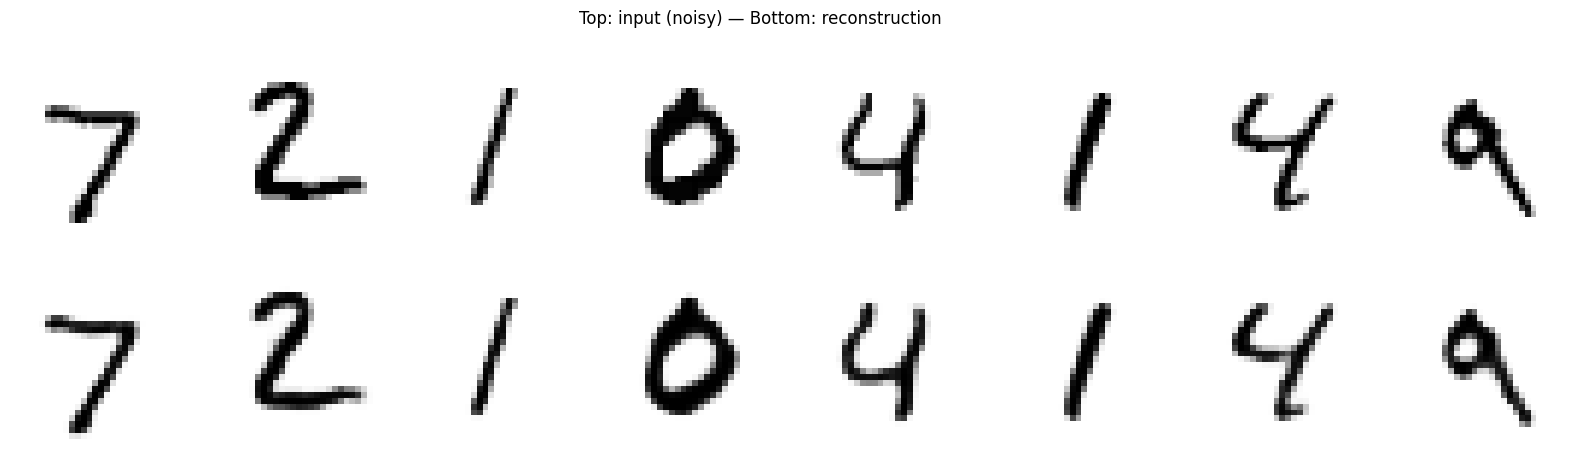

In [ ]:
# Visualize reconstructions from the convolutional autoencoder
stacked_autoencoder.eval()

plt.figure(figsize=(20, 5))
for i in range(8):
    plt.subplot(2, 8, i + 1)
    with torch.no_grad():
        inp = torch.tensor(x_test[i]).reshape(1, 28, 28).to(device)
        pred = stacked_autoencoder(inp).cpu().numpy()
    plt.imshow(x_test[i], cmap="binary")
    plt.axis("off")

    plt.subplot(2, 8, i + 8 + 1)
    plt.imshow(pred.reshape((28, 28)), cmap="binary")
    plt.axis("off")
plt.suptitle("Top: input (noisy) — Bottom: reconstruction")
plt.show()

# Part 4 — Real-World Application: Anomaly Detection

One of the most common industrial uses of autoencoders is **anomaly detection**: predictive maintenance (detecting an unusual sensor pattern before a machine fails), fraud detection, manufacturing quality control (spotting a defective part on a production line), network intrusion detection, medical imaging screening, etc.

**Core idea:** train the autoencoder **only on "normal" data**. Because the model has never seen abnormal examples, it will struggle to reconstruct them accurately — the **reconstruction error** becomes a natural anomaly score.

Here, we simulate this scenario with MNIST:
- **normal class**: digits `0`–`8`
- **anomaly**: digit `9`, which the autoencoder will *never see during training*

This mirrors a real deployment: you often don't have labeled examples of the failure/fraud/defect you are trying to catch — only examples of what "normal" looks like. That is precisely why an unsupervised approach like this can be useful, unlike the supervised classifiers from Lab 1 and Lab 2.

In [ ]:
from sklearn.metrics import (
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score,
)

### Step 1 — Isolate the "Normal" Class

We need the digit **labels** this time (`train_dataset_raw.targets` / `test_dataset_raw.targets`). We didn't need them before, since autoencoders don't require labels to reconstruct an image — but we do need them here to *simulate* an anomaly.

In [ ]:
y_train = train_dataset_raw.targets.numpy()
y_test = test_dataset_raw.targets.numpy()

NORMAL_DIGITS = list(range(9))  # digits 0-8
ANOMALY_DIGIT = 9

# Training data: ONLY normal digits — the autoencoder must never see digit 9 during training
train_mask = np.isin(y_train, NORMAL_DIGITS)
x_train_normal = x_train[train_mask]

# A small normal-only slice of the test set, used only to monitor validation loss during training
test_normal_mask = np.isin(y_test, NORMAL_DIGITS)
x_test_normal = x_test[test_normal_mask]

print("Normal training samples:", x_train_normal.shape[0])
print("Normal validation samples (for monitoring only):", x_test_normal.shape[0])

**Exercise:** build the **evaluation set** `x_eval` and its binary ground-truth labels `y_eval` (`0` = normal, `1` = anomaly) from the **test** set. This set — and only this set — will contain anomalies, and it is used **only for evaluation**, never for training.

- `eval_mask`: test images whose label is in `NORMAL_DIGITS` **or** equal to `ANOMALY_DIGIT` (hint: reuse the `np.isin` pattern from the cell above, combined with `|` for "or")
- `y_eval`: `0` for normal digits, `1` for the anomaly digit (hint: `(y_test[eval_mask] == ANOMALY_DIGIT).astype(int)`)

In [ ]:
# TODO: build x_eval and y_eval from the test set
# - eval_mask: keep test images whose label is in NORMAL_DIGITS or equals ANOMALY_DIGIT
# - x_eval: the corresponding images
# - y_eval: 0 for normal digits, 1 for the anomaly digit

eval_mask = ...
x_eval = x_test[eval_mask]
y_eval = ...

print("Evaluation samples:", x_eval.shape[0])
print("Anomalies in evaluation set:", int(y_eval.sum()))

### Step 2 — Train the Convolutional Autoencoder on Normal Data Only

We reuse the `ConvEncoder` / `ConvDecoder` architecture from Part 3, but this time we train **exclusively** on `x_train_normal`. The autoencoder should become very good at reconstructing digits 0–8, and comparatively bad at reconstructing 9 — since it has never encountered that shape.

In [ ]:
encoder = ConvEncoder().to(device)
decoder = ConvDecoder().to(device)
anomaly_autoencoder = Autoencoder(encoder, decoder).to(device)

criterion = nn.BCELoss()
optimizer = optim.Adam(anomaly_autoencoder.parameters())

history = train_autoencoder(
    anomaly_autoencoder,
    x_train_normal, x_train_normal,   # target = input, as always
    x_test_normal, x_test_normal,     # normal-only validation, just to monitor training
    criterion, optimizer, device, epochs=10,
)

### Step 3 — Turn Reconstruction Error into an Anomaly Score

**Exercise:** until now, `criterion` gave us a single loss value *averaged over an entire batch*. For anomaly detection we need **one error value per image**, so we can compare individual images against a threshold.

Complete `reconstruction_errors(model, x_data, device)` below:
- it loops over the data in batches, like `train_autoencoder` does (but only needs images, no targets)
- for each batch, compute `outputs = model(xb)`
- compute the **per-image** mean squared error: `((outputs - xb) ** 2).mean(dim=(1, 2))` — averaging over the height and width of each image, but **not** over the batch dimension, so you get one number per image
- collect the per-batch results (`.cpu().numpy()`) and concatenate them into a single array covering the whole dataset

In [ ]:
def reconstruction_errors(model, x_data, device, batch_size=64):
    model.eval()
    dataset = TensorDataset(torch.tensor(x_data))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    errors = []
    with torch.no_grad():
        for (xb,) in loader:
            # TODO:
            # - move xb to device
            # - outputs = model(xb)
            # - per_image_error = ((outputs - xb) ** 2).mean(dim=(1, 2))  # one value per image
            # - append per_image_error.cpu().numpy() to `errors`
            pass

    return np.concatenate(errors)


train_errors = reconstruction_errors(anomaly_autoencoder, x_train_normal, device)
eval_errors = reconstruction_errors(anomaly_autoencoder, x_eval, device)

print("Mean error on normal training data:", train_errors.mean())
print("Mean error on evaluation set:", eval_errors.mean())

### Step 4 — Visualize the Error Distributions

If the idea works, images of digit `9` (never seen during training) should have a visibly higher reconstruction error than normal digits.

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(eval_errors[y_eval == 0], bins=50, alpha=0.6, label="Normal (0-8)")
plt.hist(eval_errors[y_eval == 1], bins=50, alpha=0.6, label="Anomaly (9)")
plt.xlabel("Reconstruction error (MSE)")
plt.ylabel("Count")
plt.title("Reconstruction Error Distribution — Normal vs Anomaly")
plt.legend()
plt.show()

### Step 5 — Choose a Detection Threshold

**Exercise:** a common, simple choice is a high percentile of the errors on **normal training data** (data the model has already seen and should reconstruct well) — for example the 95th percentile. Any evaluation image whose error exceeds this threshold is flagged as an anomaly.

Complete the line below using `np.percentile(train_errors, 95)`.

In [ ]:
# TODO: compute the anomaly threshold as the 95th percentile of train_errors
threshold = ...

y_pred = (eval_errors > threshold).astype(int)

print("Threshold:", threshold)
print("Flagged as anomalies:", y_pred.sum(), "/", len(y_pred))

### Step 6 — Evaluate the Detector

Same tools you already used for classification in Lab 1 and Lab 2: confusion matrix, classification report, and — since a single threshold only tells part of the story — a ROC curve summarizing performance across **all** possible thresholds.

In [ ]:
cm = confusion_matrix(y_eval, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Anomaly"])
fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Anomaly Detection — Confusion Matrix")
plt.show()

print(classification_report(y_eval, y_pred, target_names=["Normal", "Anomaly"]))

In [ ]:
fpr, tpr, _ = roc_curve(y_eval, eval_errors)
auc_score = roc_auc_score(y_eval, eval_errors)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Anomaly Detection")
plt.legend()
plt.show()

### Step 7 — Inspect Individual Examples

Let's look at a few normal and anomalous digits, their reconstruction, and their error score.

In [ ]:
def show_reconstruction_examples(x_data, errors, title, n=8, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(x_data), size=min(n, len(x_data)), replace=False)

    plt.figure(figsize=(16, 4))
    for i, j in enumerate(idx):
        with torch.no_grad():
            inp = torch.tensor(x_data[j]).reshape(1, 28, 28).to(device)
            recon = anomaly_autoencoder(inp).cpu().numpy().reshape(28, 28)

        plt.subplot(2, len(idx), i + 1)
        plt.imshow(x_data[j], cmap="binary")
        plt.title(f"err={errors[j]:.4f}")
        plt.axis("off")

        plt.subplot(2, len(idx), len(idx) + i + 1)
        plt.imshow(recon, cmap="binary")
        plt.axis("off")
    plt.suptitle(title)
    plt.show()


show_reconstruction_examples(x_eval[y_eval == 0], eval_errors[y_eval == 0],
                              "Normal digits (top: input — bottom: reconstruction)")
show_reconstruction_examples(x_eval[y_eval == 1], eval_errors[y_eval == 1],
                              "Anomalous digits — 9 (top: input — bottom: reconstruction)")

### Discussion — Anomaly Detection

1. Looking at the confusion matrix and ROC-AUC, how good is this detector? Is it good enough for a real deployment (e.g., a factory quality-control line)?
2. Why does the autoencoder struggle to reconstruct digit `9`, specifically? Look at a few reconstructed anomalies above — what does the model "try" to draw instead?
3. What would happen to detection performance if a few examples of digit `9` were accidentally included in the training set?
4. In a real fraud-detection or predictive-maintenance system, why might you *not* have labeled examples of the anomaly at all, even after the fact?
5. The threshold was set using the 95th percentile of training errors. What happens to false positives and false negatives if you raise or lower this threshold? How would you decide, in a real application, whether false positives or false negatives are more costly?
6. This anomaly is very different in shape from the training data (an unseen digit). Would you expect this approach to still work well if the anomaly looked **structurally very similar** to normal data (e.g., a defect that only changes a few pixels)? What are the limits of a reconstruction-based detector?

# Final Questions

Answer these global questions at the end of the lab:

1. What is the purpose of each major stage of the notebook?
   - loading the data
   - simple dense autoencoder
   - denoising autoencoder
   - convolutional autoencoder
   - reconstruction analysis
   - anomaly detection application

2. What is an autoencoder, and how is it different from a classifier?

3. What is the role of the bottleneck or latent vector?

4. Why do we train an autoencoder with the input and target equal to each other?

5. Why can a denoising autoencoder be useful?

6. Why are convolutional layers often better than dense layers for image reconstruction?

7. What does the latent shape `1 × 64 × 3 × 3` mean in the convolutional autoencoder? *(Note the PyTorch channel-first ordering vs. the `1 × 3 × 3 × 64` shown in the original Keras notebook — same values, different axis order.)*

8. How do you judge whether a reconstruction is good?

9. What are the main limitations of these models?

10. What would you try next to improve the reconstructions?

11. What practical differences did you notice between the Keras and PyTorch versions (e.g. `Sequential` composition of an encoder/decoder into one model, explicit training loop, `BCELoss` vs the decoder's own `Sigmoid`, channel ordering `NCHW` vs `NHWC`)?
12. In the anomaly detection application, why did we train the autoencoder only on digits `0`–`8`, instead of training it on all 10 digits like the earlier parts of this lab?

13. Compare the anomaly-detection approach (Part 4) with the supervised classifiers from Lab 1 and Lab 2. What kind of problem is each one suited for, and what does each one require in terms of labeled data?